# Microarchitectural constraints

## The classic scaling era

From the mid-1970s to around 2004, processors became faster largely because transistors could be made smaller:

- Transistor miniaturisation: smaller transistors allowed more transistors to fit on a chip and generally made switching faster
- Dennard scaling: as transistors shrank, their operating voltage and current could also be reduced, allowing transistor density and performance to increase without proportionally increasing power density
- Clock frequency: processor clock speeds increased by roughly 50% per year during much of this period

Around 2004, clock speeds reached approximately 3-4 GHz and stopped increasing rapidly because of power consumption and heat. The Pentium 4 is a well-known example of this limit.

Making processors faster by simply increasing clock frequency became impractical because of thermal constraints.

## The performance triad

### Iron law

The time taken to execute a program depends on three factors:

$$
\text{Execution time} = \text{IC} \times {CPI} \times \frac{1}{f}
$$

- Instruction count (IC): Number of instructions executed. Influenced by the algorithm and compiler.
- CPI (Cycles Per Instruction): Average number of clock cycles needed per instruction. Influenced by the processor's microarchitecture.
- Clock frequency ($f$): Number of clock cycles per second. Influenced by circuit design and manufacturing technology.

### Latency vs throughput

Latency and throughput measure two aspects of processor performance:

- Latency: How long it takes to complete one task
- Throughput: How much work the processor completes per unit of time

For example, a processor might take 10 cycles to complete one operation but start a new operation every cycle:

- Latency = 10 cycles
- Throughput = 1 operation per cycle once the pipeline is full

Pipelining overlaps different stages of multiple instructions, improving throughput without necessarily reducing the time required for an individual instruction.

### Power and energy

A processor consumes power in two main ways:

- Dynamic power: Energy used when transistors switch on and off to perform computations
- Static power: Energy lost through small electrical leaks inside transistors, even when they are not switching

Increasing clock speed or voltage generally increases power consumption.

This creates two important limits:

- Thermal Design Power (TDP): The amount of heat the processor's cooling system is designed to handle under specified conditions. Too much heat can cause the processor to reduce its speed to protect itself
- Energy consumption: The total amount of energy used to complete a task. Running at high power for longer consumes more energy

Making a processor faster often increases its power consumption and heat output. Therefore, processor designers must balance performance against power and energy efficiency, rather than simply maximising speed.

## Dark silicon

Dark silicon is the part of a processor chip that cannot be used at full power and full speed simultaneously because of power and heat limits.

Although a chip may physically contain billions of transistors, it cannot necessarily operate all of them at once without exceeding its Thermal Design Power (TDP).

- Dark silicon: Hardware that is switched off.
- Dim silicon: Hardware that operates at reduced speed or power.

Adding additional identical cores to allow tasks to be run in parallel helps to improve performance, but eventually provides diminishing returns:

- More active cores consume more power and generate more heat.
- The processor may have to reduce clock speeds to stay within thermal limits.
- Some parts of a program cannot be parallelised, limiting the benefit of extra cores

Instead of using only identical general-purpose cores, modern processors combine different types of specialised hardware. These specialised units can perform certain tasks using much less energy than a general-purpose CPU. They can also be switched off when not needed.

# Processor & pipeline fundamentals

## MIPS processors 

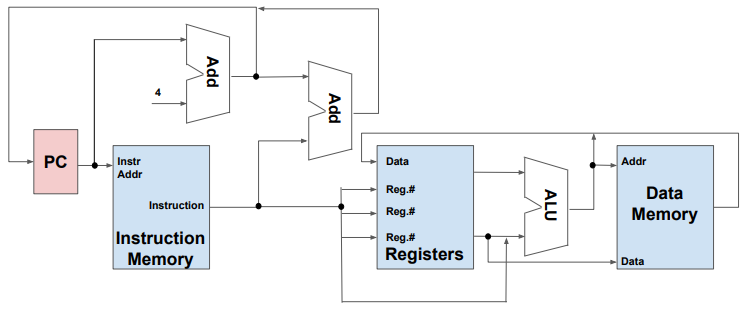

The main components of a MIPS processor are:

- PC (Program Counter): Stores the address of the next instruction to fetch.
- Instruction Memory: Stores the program's instructions. The PC supplies the address of the instruction to read.
- Registers: Store small amounts of data that instructions operate on, such as operands and intermediate results.
- Data Memory: Stores data that instructions can read or write, for example when executing load and store instructions.
- Address / Data lines: Carry addresses to memory and transfer instructions or data between components.

For a typical instruction:

- Fetch: The PC gives the instruction memory an address, and the instruction is retrieved.
- Update PC: The processor calculates the next sequential address, PC + 4 (instructions are usually 4 bytes long).
- Execute: The instruction operates on registers or calculates a memory address.
- Access memory if needed: Load and store instructions read or write data memory.
- Write back if needed: The result is written to a register.

## Pipelining

Pipelining is a technique that allows a processor to work on multiple instructions at the same time by processing them at different stages.

A typical instruction passes through five stages:
1. IF - Instruction Fetch: Retrieve the instruction from memory.
2. ID - Instruction Decode: Work out what the instruction does and identify its operands.
3. EX - Execute: Perform the calculation or operation.
4. MEM - Memory Access: Read or write data memory if required.
5. WB - Write Back: Store the result in a register if required.

For example, without pipelining, the processor might complete one instruction before starting the next. With pipelining, while instruction 1 executes, instruction 2 can be decoded and instruction 3 can be fetched.

The main benefit is increased throughput - more instructions completed per unit of time. Pipelining does not necessarily make an individual instruction finish faster.

### Pipeline hazards

A pipeline hazard is a situation that prevents the next instruction from progressing in its intended clock cycle.

Hazards can force the processor to pause the pipeline or discard instructions that were fetched speculatively.

There are three main types.

#### Structural hazards

A structural hazard occurs when two instructions need the same hardware resource at the same time, but the processor cannot support both operations simultaneously. 

Both instructions cannot proceed as planned, so one must wait.

The solution is to provide separate resources, such as separate instruction and data memories, or stall one instruction.

#### Data hazards

A data hazard occurs when an instruction needs a result that a previous instruction has not produced yet.

The solution is forwarding (passing a result directly between pipeline stages) or stalling until the data is available.

#### Control hazards

A control hazard occurs when the processor does not yet know which instruction should execute next, usually because of a branch or jump.

For example, 
```
BEQ R1, R2, TARGET
ADD R3, R4, R5
```

The `BEQ` instruction branches to `TARGET` if `R1` equals `R2`. Before the branch outcome is known, the processor may fetch the `ADD` instruction. If the branch is taken, that `ADD` may be the wrong instruction and must be discarded.

The solution is to use branch prediction, resolve branches earlier, or stalling until the outcome is known.

### Dynamic branch prediction

Dynamic branch prediction uses the observed behaviour of branches during program execution to predict their future outcomes.

It uses a Branch History Table (BHT), a small table that stores prediction information about branches:

- The branch instruction's address is used to index the table, often using some of its lower bits.
- The table stores a prediction, such as whether the branch is likely to be taken or not taken.
- The prediction is updated based on the actual outcome when the branch executes.

For example, if a loop branch has repeatedly been taken, the processor may predict that it will be taken again.

Unlike static prediction, which follows a fixed rule, dynamic prediction learns from execution history.